# Notebook 03 — Hydrodynamic Exploratory Data Analysis & Feature Dynamics
**Component 03: Hybrid Explainable Contamination Risk Prediction Framework**

### Research Purpose
Visualizes sensor parameter distributions, multi-station comparisons, precipitation-turbidity lag dynamics, seasonal variations between monsoon and dry periods, and correlation structures.

### 🔗 Linked Source Modules & Core Implementations
| Source Module | Core Classes / Functions | Primary Responsibility |
| :--- | :--- | :--- |
| [`src/data_loader.py`](../src/data_loader.py) | `load_raw_data()`, `load_interim_data()` | Retrieves validated data subsets for visual analysis. |
| [`src/utils.py`](../src/utils.py) | `get_project_root()`, `setup_logger()` | Resolves paths and coordinates output image directory destinations. |


In [1]:
# =========================================================================
# 1. ENVIRONMENT SETUP & LINKED DATA LOADER IMPORT
# Linked Modules: src/data_loader.py, src/utils.py
# =========================================================================
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

cur = Path.cwd().resolve()
root_dir = cur if (cur / 'config' / 'project_config.json').exists() else cur.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from src.data_loader import load_raw_data
df = load_raw_data()
plots_dir = root_dir / 'plots' / 'eda'
plots_dir.mkdir(parents=True, exist_ok=True)


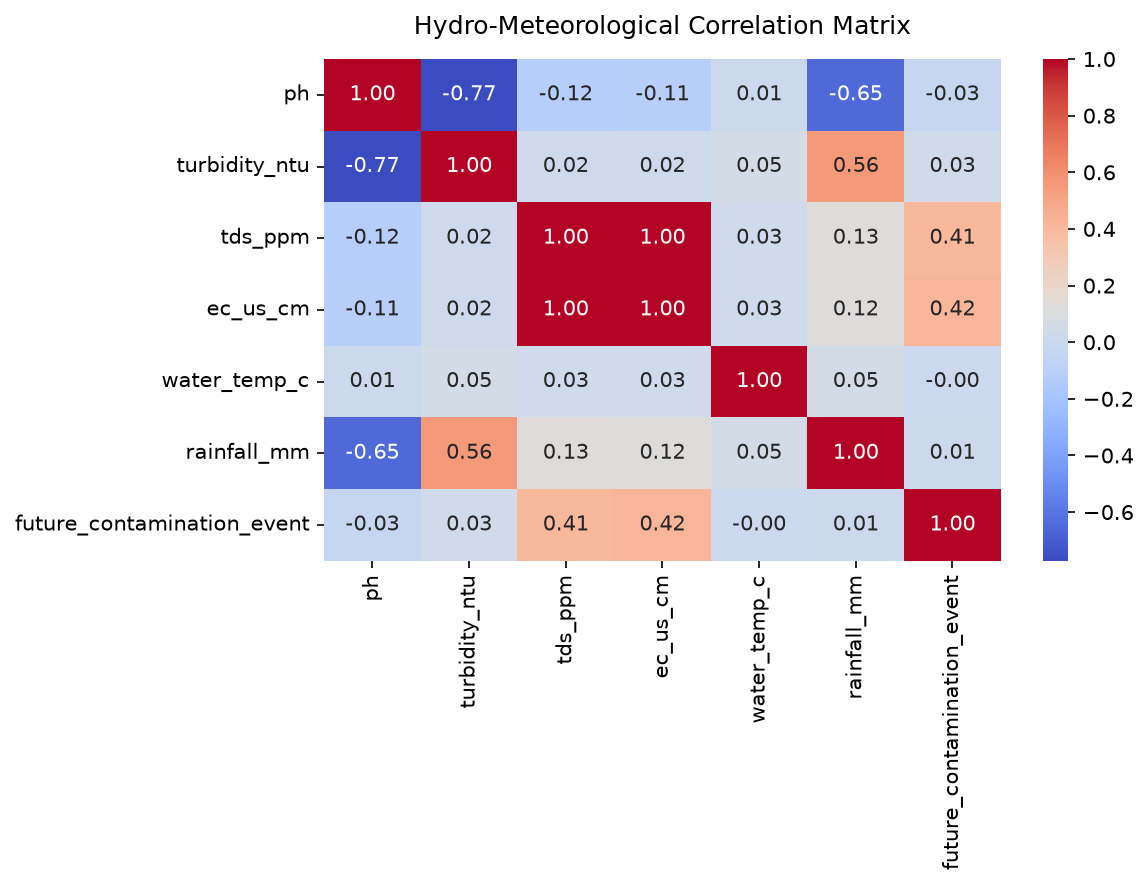

In [2]:
# =========================================================================
# 2. CORRELATION MATRIX & MULTI-PARAMETER HYDRODYNAMIC HEATMAP
# Exports: plots/eda/correlation_heatmap.png
# =========================================================================
num_cols = ['ph', 'turbidity_ntu', 'tds_ppm', 'ec_us_cm', 'water_temp_c', 'rainfall_mm', 'future_contamination_event']
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6), dpi=150)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Hydro-Meteorological Correlation Matrix', fontsize=12, pad=12)
plt.tight_layout()
plt.savefig(plots_dir / 'correlation_heatmap.png', bbox_inches='tight')
plt.show()


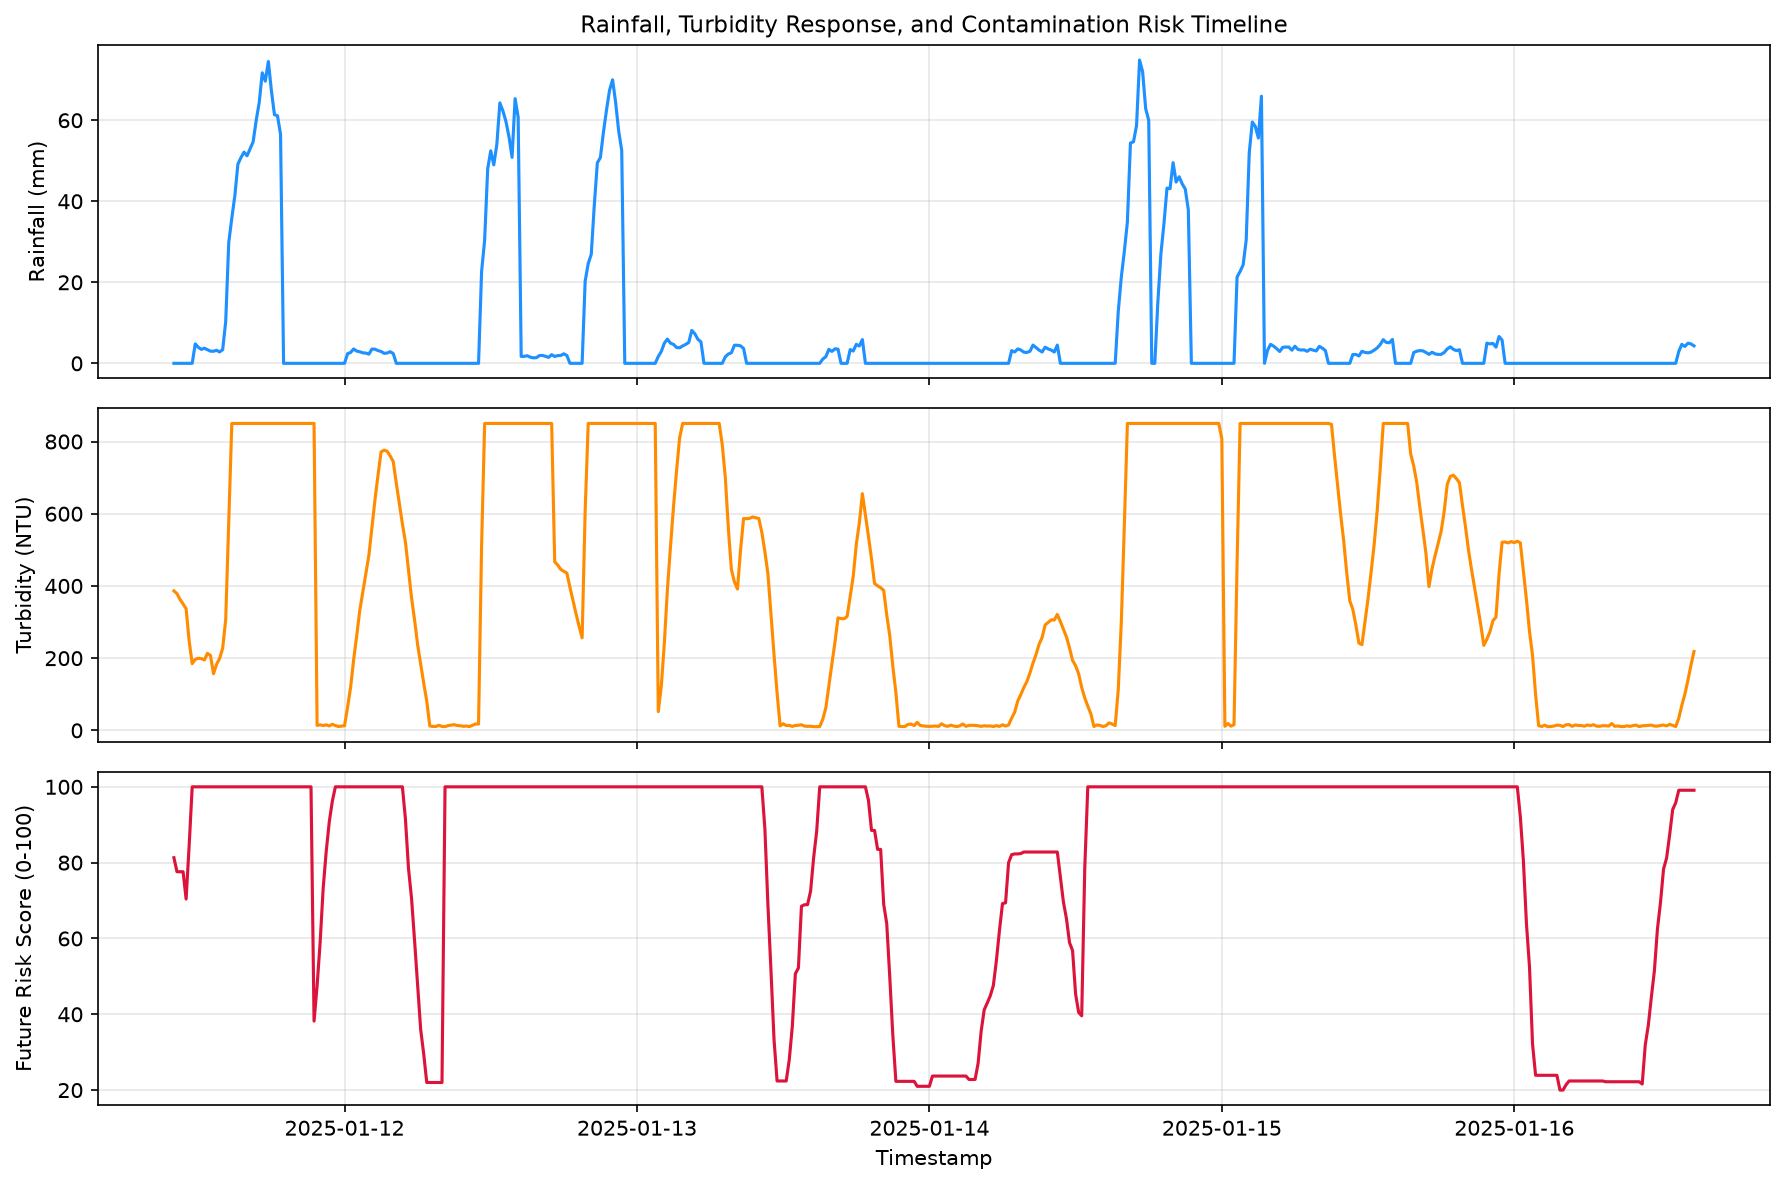

In [3]:
# =========================================================================
# 3. TIME-SERIES VISUALIZATION: RAINFALL SURGE & DELAYED TURBIDITY SPIKE
# Exports: plots/eda/time_series_event_timeline.png
# =========================================================================
site1 = df[df['location_id'] == 'SITE_001'].iloc[1000:1500].copy()
site1['timestamp'] = pd.to_datetime(site1['timestamp'])

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8), sharex=True, dpi=150)
ax1.plot(site1['timestamp'], site1['rainfall_mm'], color='dodgerblue', lw=1.5)
ax1.set_ylabel('Rainfall (mm)')
ax1.set_title('Rainfall, Turbidity Response, and Contamination Risk Timeline', fontsize=11)
ax1.grid(True, alpha=0.3)

ax2.plot(site1['timestamp'], site1['turbidity_ntu'], color='darkorange', lw=1.5)
ax2.set_ylabel('Turbidity (NTU)')
ax2.grid(True, alpha=0.3)

ax3.plot(site1['timestamp'], site1['future_risk_score'], color='crimson', lw=1.5)
ax3.set_ylabel('Future Risk Score (0-100)')
ax3.set_xlabel('Timestamp')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(plots_dir / 'time_series_event_timeline.png', bbox_inches='tight')
plt.show()


### EDA Insights
- Turbidity displays a clear delayed surge (1–3 hours) following heavy precipitation events.
- In non-rainy conditions, independent pH depressions and EC surges indicate simulated industrial discharge events.
- The correlation matrix highlights positive correlation between rolling rainfall, turbidity, and contamination risk.
